In [8]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.util import img_as_ubyte
from skimage.color import rgb2gray

In [9]:
moon = data.moon()
moon.shape, moon.dtype, moon.min(), moon.max()

((512, 512), dtype('uint8'), np.uint8(0), np.uint8(255))

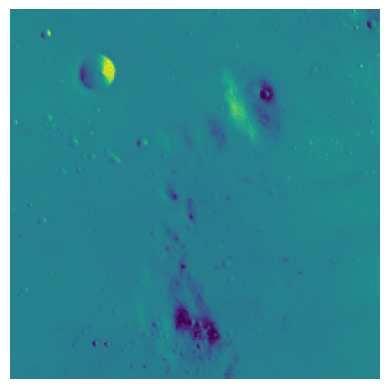

In [10]:
plt.axis("off")
plt.imshow(moon)

In [11]:
moon_uint = img_as_ubyte(moon)
moon_uint.shape, moon_uint.dtype, moon_uint.min(), moon_uint.max()

((512, 512), dtype('uint8'), np.uint8(0), np.uint8(255))

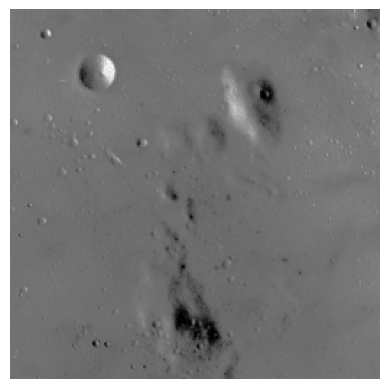

In [12]:
plt.axis("off")
plt.imshow(moon_uint, cmap="gray")

In [13]:
def implot(img, img_filt, nomefiltro, kernelsize):
  plt.figure(figsize=(12,12))
  plt.subplot(1,2,1)
  plt.imshow(img, cmap="gray")
  plt.title("Imagem Original")
  plt.axis("off")

  plt.subplot(1,2,2)
  plt.imshow(img_filt, cmap="gray")
  plt.title("Filtro " + nomefiltro + ' ' + kernelsize)
  plt.axis("off")

  plt.show()

# Criando a função de convolução e as de operações

In [14]:
def _window_from_image(img, interval: int, center_coordinates: tuple):
  return img[
      center_coordinates[0]:center_coordinates[0]+interval,
      center_coordinates[1]:center_coordinates[1]+interval
  ]


In [15]:
def convolute_img(gray_img, kernel):
  padded_img = np.pad(array=gray_img, pad_width=len(kernel)//2)

  new_img = np.zeros(shape=gray_img.shape, dtype=float)

  for i in range(gray_img.shape[0]):
    for j in range(gray_img.shape[1]):
      window = _window_from_image(padded_img, len(kernel), (i,j))

      new_img[i,j] = (window * kernel).sum()

  new_img_uint = np.round(a=new_img,decimals=0).astype(np.uint8)
  return new_img_uint


In [16]:
def image_filter(gray_img, window_size, operation):
  padded_img = np.pad(array=gray_img, pad_width=window_size//2)

  new_img = np.zeros(shape=gray_img.shape, dtype=float)

  for i in range(gray_img.shape[0]):
    for j in range(gray_img.shape[1]):
      window = _window_from_image(padded_img, window_size, (i,j))

      match operation:
        case "median":
          new_img[i,j] = np.median(window)
        case "max":
          new_img[i,j] = np.max(window)
        case "mode":
          count_value = np.bincount(window.ravel())
          new_img[i,j] = np.argmax(count_value)
        case _:
          raise ValueError("Operação Inválida")

  new_img_uint = np.round(a=new_img,decimals=0).astype(np.uint8)
  return new_img_uint


In [17]:
def mean_filter(gray_img, window_size):

  kernel = np.ones((window_size, window_size))

  normalized_kernel = kernel / np.sum(kernel)

  filtered_img = convolute_img(gray_img, normalized_kernel)

  return filtered_img

In [18]:
mean_filtered_moon = mean_filter(moon_uint, 5)

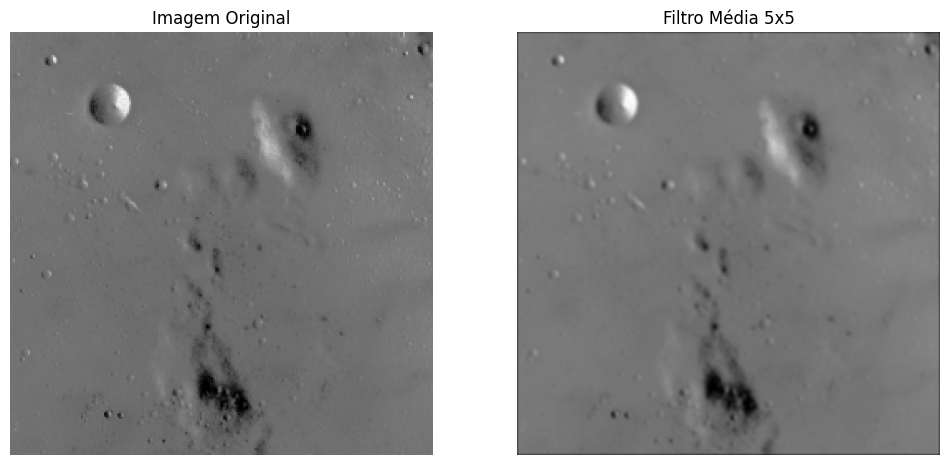

In [19]:
implot(moon_uint, mean_filtered_moon, "Média", "5x5")

In [20]:
def median_filter(gray_img, window_size):

  filtered_img = image_filter(gray_img, window_size, operation="median")

  return filtered_img

In [21]:
median_filtered_moon = median_filter(moon_uint, 5)

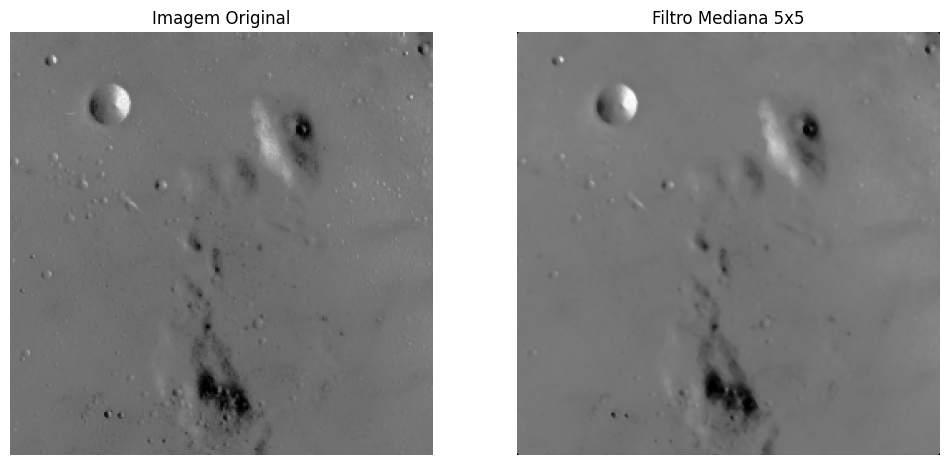

In [22]:
implot(moon_uint, median_filtered_moon, "Mediana", "5x5")

In [23]:
def max_filter(gray_img, window_size):

  filtered_img = image_filter(gray_img, window_size, operation="max")

  return filtered_img

In [24]:
max_filtered_moon = max_filter(moon_uint, 5)

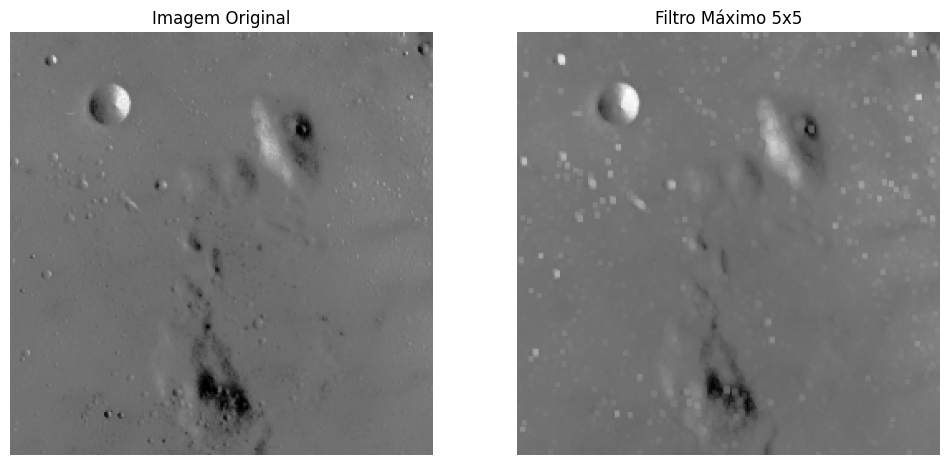

In [25]:
implot(moon_uint, max_filtered_moon, "Máximo", "5x5")

In [26]:
def mode_filter(gray_img, window_size):

  filtered_img = image_filter(gray_img, window_size, operation="mode")

  return filtered_img

In [27]:
mode_filtered_moon = mode_filter(moon_uint, 5)

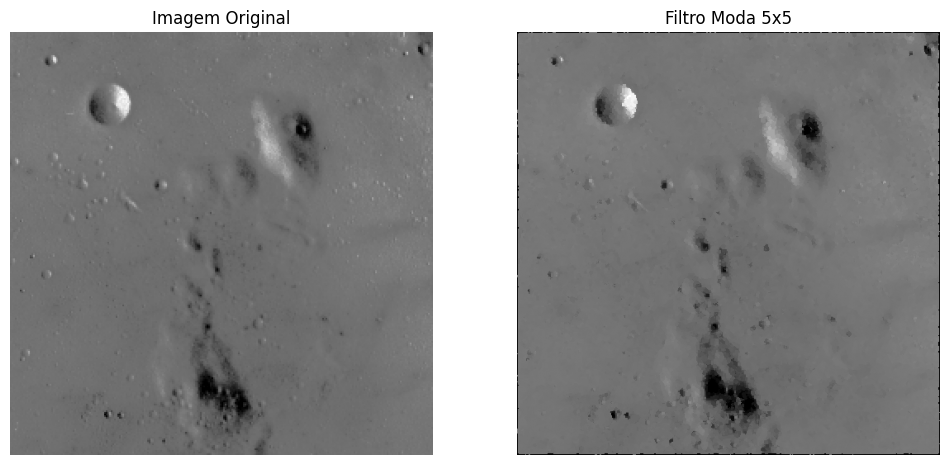

In [28]:
implot(moon_uint, mode_filtered_moon, "Moda", "5x5")